# 05 · Experimento: baseline y variantes de los datos, en detalle

Este cuaderno **no necesita GPU**. Lee las predicciones y tablas ya guardadas en el repositorio (el baseline clásico de `run_baseline_variantes.py` y el monoagente de `monoagente_salamandra.py`, corrido en el cuaderno 04) y muestra el detalle:

1. Qué cambia cada variante de datos y cuántos tuits toca.
2. Baseline clásico (TF-IDF + regresión logística), con la variante limpia y con cada componente.
3. Monoagente con Salamandra-7B-Instruct, con las mismas variantes.
4. Monoagente contra baseline: por variedad, qué clases predice y dónde se equivoca.
5. Verificación de que las tablas guardadas salen de las predicciones.

Métrica principal: Macro-F1 en *dev* (2.465 tuits), con IC 95% por bootstrap. Las variantes se comparan con **diferencia pareada** sobre los mismos tuits. No existe partición de prueba: todo se reporta en dev.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200, "display.max_colwidth", 90)
RAIZ = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
for sub in ("experimento", "eda", "features"):
    sys.path.append(str(RAIZ / "scripts" / sub))
import eda_utils as E
import variantes_datos as V
import evaluacion as EV

T_CLA = RAIZ / "docs/experimento/tablas"
T_LLM = RAIZ / "docs/experimento/llm/tablas"
AZUL, GRIS, ROJO = "#2a78d6", "#b8b7b0", "#c0392b"
CLASES = ["NEG", "NEU", "POS"]

corpus = E.cargar_corpus(RAIZ / "data")
dev = corpus[corpus.split == "dev"].reset_index(drop=True)
print("tuits en dev:", len(dev), "| variedades:", sorted(dev.variedad.unique()))

tuits en dev: 2465 | variedades: ['CR', 'ES', 'MX', 'PE', 'UY']


## 1 · Qué cambia cada variante

Todas parten del texto **base** (el que ve el LLM: `@USUARIO`, `URL`, espacios colapsados). La variante principal es **limpio**; las demás cambian un solo componente, para saber cuál pesa. El conteo de abajo es sobre los 2.465 tuits de dev: cuántos textos cambian respecto de la base.

In [2]:
base_txt = dev["texto"].map(V.base)
filas = []
for nombre in V.VARIANTES:
    t = dev["texto"].map(lambda x: V.aplicar(x, nombre))
    filas.append({"variante": nombre, "qué cambia": V.DESCRIPCION[nombre],
                  "tuits que cambian": int((t != base_txt).sum()),
                  "% de dev": round(100 * (t != base_txt).mean(), 1)})
tabla_var = pd.DataFrame(filas)
tabla_var

,variante,qué cambia,tuits que cambian,% de dev
0,base,"Tuit como lo ve el LLM (@USUARIO, URL, espacios colapsados)",0,0.0
1,limpio,Minúsculas + sin tildes + sin alargamientos + sin emojis,2408,97.7
2,minusculas,Solo minúsculas,2358,95.7
3,sin_tildes,Solo sin tildes (conserva ñ),1423,57.7
4,sin_alargamientos,Solo sin letras alargadas,119,4.8
5,sin_emojis,Solo sin emojis,13,0.5
6,sin_usuario_url,Extra: sin los marcadores @USUARIO y URL,1212,49.2


Lectura: `minusculas` toca casi todos los textos (96%) y `sin_tildes` más de la mitad (58%). `sin_alargamientos` toca 5% y `sin_emojis` apenas 13 tuits (0,5%). Además, TF-IDF ya pasa todo a minúsculas y esos 13 emojis no cambian ninguna predicción, así que `minusculas` y `sin_emojis` no pueden mover nada en el baseline clásico (0 predicciones distintas en la tabla de la sección 2).

In [3]:
ej = pd.read_csv(T_CLA / "ejemplos_variantes.csv")
for _, r in ej.iterrows():
    print(f"[{r.variedad}] base  : {r.base}\n     limpio: {r.limpio}\n")

[UY] base  : Horas y me voy a la mierda!! tres días incomunicada, aislada, en paz, que lindooooo!
     limpio: horas y me voy a la mierda!! tres dias incomunicada, aislada, en paz, que lindo!

[PE] base  : Ayeeer en Sasuke Shinden! JAJAJA que letra mas fea debe ser de naruto. Por otro lado la policía militar
     limpio: ayer en sasuke shinden! jajaja que letra mas fea debe ser de naruto. por otro lado la policia militar

[PE] base  : @USUARIO @USUARIO siii !! eso haré !! yo no ubico esa publicación alucina ! que raro
     limpio: @usuario @usuario si !! eso hare !! yo no ubico esa publicacion alucina ! que raro

[PE] base  : No debí cogerme la cara con las manos suciaaaaas!!
     limpio: no debi cogerme la cara con las manos sucias!!

[MX] base  : @USUARIO aaaaajajajajajajajajaj pues me lo rompió, y yo diciéndote hace una semana era mi todo hahaha
     limpio: @usuario ajajajajajajajajaj pues me lo rompio, y yo diciendote hace una semana era mi todo hahaha



## 2 · Baseline clásico: TF-IDF + regresión logística

TF-IDF de n-gramas de palabras (1 a 2) con regresión logística balanceada, sin ajustar hiperparámetros. Se ajusta **solo con train** y se mide **solo en dev**. La variante se aplica igual a train y a dev.

In [4]:
res_cla = pd.read_csv(T_CLA / "resultados_por_variante.csv")
dif_cla = pd.read_csv(T_CLA / "diferencias_pareadas_variantes.csv")
ancho = (res_cla[res_cla.variante.isin(["base", "limpio"])]
         .pivot(index="ambito", columns="variante", values="macro_f1")
         .reindex(["Todas", "CR", "ES", "MX", "PE", "UY"]))
d = dif_cla[dif_cla.variante == "limpio"].set_index("ambito")
ancho["diferencia"] = d["dif_macro_f1"]
ancho["IC 95%"] = d.apply(lambda r: f"{r.ic_inf:+.3f} a {r.ic_sup:+.3f}", axis=1)
ancho["cambian"] = d.apply(lambda r: f"{int(r.predicciones_distintas)} de {int(r.n_dev)}", axis=1)
ancho["conclusión"] = d["conclusion"]
ancho

variante,base,limpio,diferencia,IC 95%,cambian,conclusión
ambito,,,,,,
Todas,0.5556,0.5570,0.0014,-0.008 a +0.011,178 de 2465,no se distingue
CR,0.5864,0.5860,-0.0004,-0.020 a +0.020,16 de 390,no se distingue
ES,0.5382,0.5390,0.0008,-0.020 a +0.020,49 de 581,no se distingue
MX,0.5587,0.5569,-0.0018,-0.027 a +0.023,41 de 510,no se distingue
PE,0.5010,0.5030,0.0020,-0.020 a +0.023,41 de 498,no se distingue
UY,0.5673,0.5755,0.0082,-0.011 a +0.026,31 de 486,no se distingue


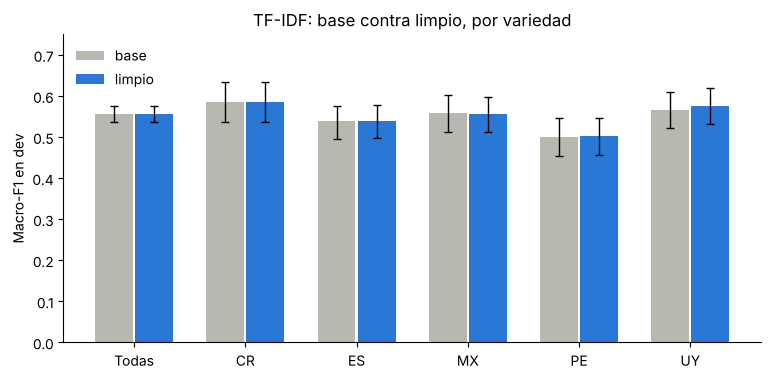

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
amb = list(ancho.index); x = np.arange(len(amb))
for off, var, col in ((-0.18, "base", GRIS), (0.18, "limpio", AZUL)):
    s = res_cla[res_cla.variante == var].set_index("ambito").loc[amb]
    ax.bar(x + off, s["macro_f1"], 0.34, color=col, label=var)
    ax.errorbar(x + off, s["macro_f1"], yerr=[s["macro_f1"] - s["ic_inf"], s["ic_sup"] - s["macro_f1"]], fmt="none", ecolor="k", capsize=3, lw=1)
ax.set_xticks(x, amb); ax.set_ylim(0, 0.75); ax.set_ylabel("Macro-F1 en dev")
ax.set_title("TF-IDF: base contra limpio, por variedad"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

### Cada componente por separado (baseline clásico)

Diferencia de Macro-F1 contra la base, en todo dev, con IC 95% pareado. Si el intervalo contiene 0, no se distingue de la base.

In [6]:
c = dif_cla[dif_cla.ambito == "Todas"].copy()
c["IC 95%"] = c.apply(lambda r: f"{r.ic_inf:+.3f} a {r.ic_sup:+.3f}", axis=1)
c[["variante", "predicciones_distintas", "variante_acierta_y_base_no", "base_acierta_y_variante_no", "dif_macro_f1", "IC 95%", "p_bootstrap", "conclusion"]].reset_index(drop=True)

,variante,predicciones_distintas,variante_acierta_y_base_no,base_acierta_y_variante_no,dif_macro_f1,IC 95%,p_bootstrap,conclusion
0,limpio,178,72,69,0.0014,-0.008 a +0.011,0.786,no se distingue
1,minusculas,0,0,0,0.0000,+0.000 a +0.000,1.000,no se distingue
2,sin_tildes,166,70,63,0.0031,-0.007 a +0.013,0.493,no se distingue
3,sin_alargamientos,48,21,13,0.0034,-0.001 a +0.008,0.146,no se distingue
4,sin_emojis,0,0,0,0.0000,+0.000 a +0.000,1.000,no se distingue
5,sin_usuario_url,238,97,96,0.0009,-0.010 a +0.012,0.885,no se distingue


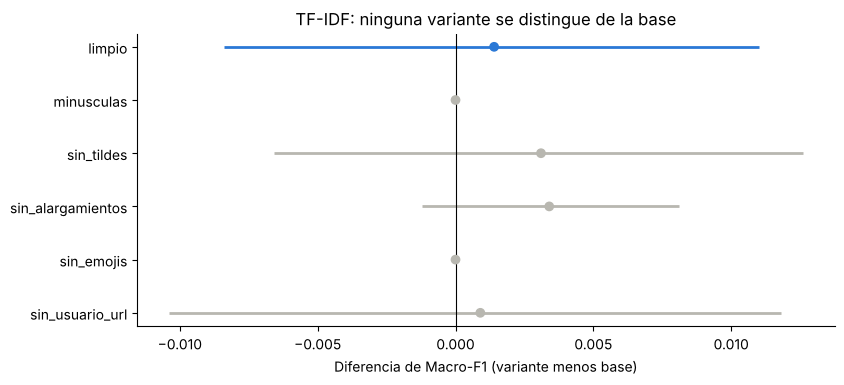

In [7]:
c = c.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.8)); y = np.arange(len(c))
ax.hlines(y, c.ic_inf, c.ic_sup, color=[AZUL if v == "limpio" else GRIS for v in c.variante], lw=2)
ax.scatter(c.dif_macro_f1, y, color=[AZUL if v == "limpio" else GRIS for v in c.variante], zorder=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y, c.variante)
ax.set_xlabel("Diferencia de Macro-F1 (variante menos base)"); ax.set_title("TF-IDF: ninguna variante se distingue de la base")
ax.spines[["top", "right"]].set_visible(False); plt.show()

**Cómo leer las columnas.** *predicciones_distintas* es cuántos tuits cambian de predicción; *variante_acierta_y_base_no* y *base_acierta_y_variante_no* dicen en qué dirección. Cuando las dos cifras se parecen, el cambio sube y baja el resultado a la vez y el neto es casi cero.

## 3 · Monoagente con Salamandra-7B-Instruct

`BSC-LT/salamandra-7b-instruct`, revisión `a3ed5452fafb3698a0423b1a18bfb5888f4e611b`, 4 bits, zero-shot, salida JSON, temperatura 0, hasta 2 reintentos. Prompt `B1-v1`, sin la variedad. Una salida que no se entiende cuenta como NEU.

In [8]:
pred = pd.read_csv(RAIZ / "docs/experimento/llm/predicciones_llm.csv", dtype=str, keep_default_na=False)
print("filas:", len(pred), "| ids únicos por variante:", pred.groupby("variante").id.nunique().to_dict(),
      "| duplicados:", int(pred.duplicated(["id", "variante"]).sum()))
print("intentos:", pred.intentos.value_counts().to_dict())
print("salidas inválidas:"); display(pd.read_csv(T_LLM / "salidas_invalidas.csv"))

filas: 4930 | ids únicos por variante: {'base': 2465, 'limpio': 2465} | duplicados: 0
intentos: {'1': 4921, '3': 9}
salidas inválidas:


,variante,n,salidas_invalidas,pct_invalidas
0,base,2465,4,0.16
1,limpio,2465,3,0.12


In [9]:
res_llm = pd.read_csv(T_LLM / "resultados_llm_por_variante.csv")
dif_llm = pd.read_csv(T_LLM / "diferencias_llm_pareadas.csv")
a2 = (res_llm.pivot(index="ambito", columns="variante", values="macro_f1").reindex(["Todas", "CR", "ES", "MX", "PE", "UY"]))
d = dif_llm.set_index("ambito")
a2["diferencia"] = d["dif_macro_f1"]; a2["IC 95%"] = d.apply(lambda r: f"{r.ic_inf:+.3f} a {r.ic_sup:+.3f}", axis=1)
a2["cambian"] = d.apply(lambda r: f"{int(r.predicciones_distintas)} de {int(r.n_dev)}", axis=1)
a2["conclusión"] = d["conclusion"]
a2

variante,base,limpio,diferencia,IC 95%,cambian,conclusión
ambito,,,,,,
Todas,0.4793,0.4821,0.0028,-0.009 a +0.014,206 de 2465,no se distingue
CR,0.5040,0.5098,0.0057,-0.026 a +0.040,35 de 390,no se distingue
ES,0.4525,0.4673,0.0148,-0.008 a +0.038,46 de 581,no se distingue
MX,0.4298,0.4242,-0.0056,-0.031 a +0.021,52 de 510,no se distingue
PE,0.4920,0.4851,-0.0069,-0.040 a +0.024,54 de 498,no se distingue
UY,0.5161,0.5211,0.0050,-0.013 a +0.023,19 de 486,no se distingue


La variante limpia **tampoco** mueve al LLM: cambia 206 de 2.465 predicciones, 87 a favor y 84 en contra. Un LLM sí distingue mayúsculas, tildes y alargamientos, así que no era obvio de antemano; el resultado es que, con este prompt, no importa.

## 4 · Monoagente contra baseline

Misma variante (`base`), mismos tuits. Diferencia = LLM menos TF-IDF.

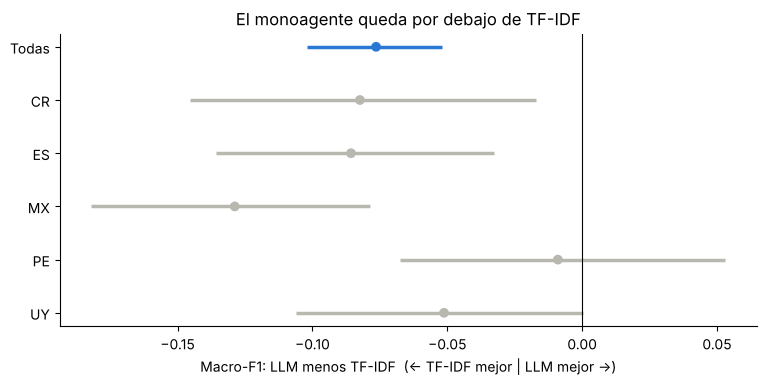

,n_dev,dif_macro_f1,ic_inf,ic_sup,p_bootstrap,conclusion
ambito,,,,,,
Todas,2465,-0.0764,-0.1020,-0.0518,0.000,TF-IDF mejor
CR,390,-0.0824,-0.1454,-0.0171,0.012,TF-IDF mejor
ES,581,-0.0857,-0.1358,-0.0327,0.002,TF-IDF mejor
MX,510,-0.1288,-0.1820,-0.0786,0.000,TF-IDF mejor
PE,498,-0.0090,-0.0676,0.0531,0.775,no se distingue
UY,486,-0.0512,-0.1060,0.0003,0.051,no se distingue


In [10]:
par = pd.read_csv(T_LLM / "llm_vs_clasico_pareado.csv")
par["conclusion"] = par["conclusion"].replace({"A mejor": "TF-IDF mejor", "B mejor": "LLM mejor"})
pb = par[par.variante.str.contains("base")].set_index("ambito").reindex(["Todas", "CR", "ES", "MX", "PE", "UY"])
fig, ax = plt.subplots(figsize=(9, 3.8)); y = np.arange(len(pb))[::-1]
col = [AZUL if a == "Todas" else GRIS for a in pb.index]
ax.hlines(y, pb.ic_inf, pb.ic_sup, color=col, lw=2.5); ax.scatter(pb.dif_macro_f1, y, color=col, zorder=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y, pb.index)
ax.set_xlabel("Macro-F1: LLM menos TF-IDF  (← TF-IDF mejor | LLM mejor →)")
ax.set_title("El monoagente queda por debajo de TF-IDF"); ax.spines[["top", "right"]].set_visible(False); plt.show()
pb[["n_dev", "dif_macro_f1", "ic_inf", "ic_sup", "p_bootstrap", "conclusion"]]

Con 5 variedades, una corrección de Bonferroni exige p < 0,01. La pasan ES y MX; CR (p = 0,012) queda en el límite; PE y UY no se distinguen.

### Qué clases predice cada modelo

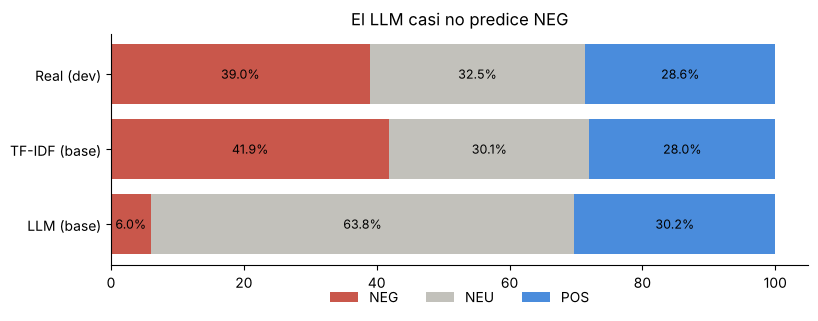

,Real (dev),TF-IDF (base),LLM (base)
clase,,,
NEG,38.95,41.91,5.96
NEU,32.45,30.10,63.81
POS,28.60,27.99,30.22


In [11]:
dist = pd.read_csv(T_LLM / "distribucion_predicha.csv").set_index("clase")
dist = dist[["real", "clasico_base", "llm_base"]]
dist.columns = ["Real (dev)", "TF-IDF (base)", "LLM (base)"]
fig, ax = plt.subplots(figsize=(9, 3))
izq = np.zeros(3); colores = {"NEG": ROJO, "NEU": GRIS, "POS": AZUL}
for c_ in CLASES:
    v = dist.loc[c_].to_numpy()
    ax.barh(dist.columns, v, left=izq, color=colores[c_], label=c_, alpha=.85)
    for i, (l, w) in enumerate(zip(izq, v)): ax.text(l + w / 2, i, f"{w:.1f}%", ha="center", va="center", fontsize=9)
    izq += v
ax.invert_yaxis(); ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.05))
ax.set_title("El LLM casi no predice NEG"); ax.spines[["top", "right"]].set_visible(False); plt.show()
dist

In [12]:
f1 = pd.read_csv(T_LLM / "f1_por_clase.csv")
f1[f1.modelo.isin(["clasico_base", "llm_base"])].pivot(index="clase", columns="modelo", values=["precision", "recobrado", "f1"])

precision             recobrado                    f1         
modelo clasico_base llm_base clasico_base llm_base clasico_base llm_base
clase                                                                   
NEG          0.6070   0.9320       0.6531   0.1427       0.6292   0.2475
NEU          0.4690   0.3891       0.4350   0.7650       0.4514   0.5158
POS          0.5928   0.6564       0.5801   0.6936       0.5864   0.6745

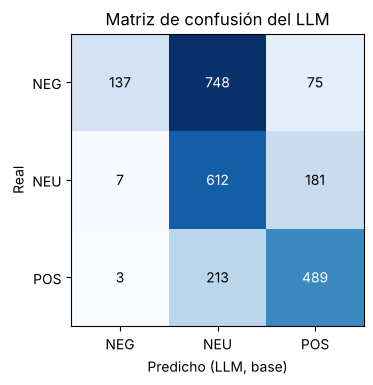

NEG reales marcados como NEU: 748 de 960


In [13]:
mc = pd.read_csv(T_LLM / "matriz_confusion_llm.csv").set_index("real")
fig, ax = plt.subplots(figsize=(4.6, 3.8)); im = ax.imshow(mc.values, cmap="Blues")
ax.set_xticks(range(3), mc.columns); ax.set_yticks(range(3), mc.index)
ax.set_xlabel("Predicho (LLM, base)"); ax.set_ylabel("Real")
for i in range(3):
    for j in range(3):
        ax.text(j, i, mc.values[i, j], ha="center", va="center", color="white" if mc.values[i, j] > 400 else "black")
ax.set_title("Matriz de confusión del LLM"); plt.show()
print("NEG reales marcados como NEU:", mc.loc["NEG", "NEU"], "de", mc.loc["NEG"].sum())

La fila NEG concentra el problema: de 960 tuits negativos, 748 salen como NEU. Cuando el LLM dice NEG casi siempre acierta (precisión 0,93), pero encuentra pocos (recobrado 0,14). En POS y NEU el LLM supera a TF-IDF en F1, así que la pérdida total viene de NEG.

**Hipótesis (no probada):** el prompt `B1-v1` empuja a NEU ante la duda. Perú, donde NEU es la clase mayoritaria (55,2%), es la variedad donde menos pierde.

### Ejemplos de error: NEG real que el LLM marca NEU

In [14]:
pb_ = pred[pred.variante == "base"].merge(dev[["id", "texto"]].assign(id=lambda d: d.id.astype(str)), on="id")
err = pb_[(pb_.etiqueta == "NEG") & (pb_.pred == "NEU")].sample(10, random_state=0)
err[["variedad", "texto", "salida_cruda"]].reset_index(drop=True)

,variedad,texto,salida_cruda
0,CR,"Al chile no hay ninguna foto en la que me etiqueten que no parezca que digo ""miren que...","{""label"": ""NEU""}"
1,MX,"¿Se venden? ¿No, verdad? Bueno, pues sSu tiempo tampoco. El mío tampoco. espero puedan...",NEU
2,ES,ah bueno y no tengo dinero,NEU
3,ES,"@fonzeff @malenko_ @girotix Eso me temo, mucho calor y mucha gente por todos lados, lo...","{""label"": ""NEU""}"
4,PE,"Buenos días, ya casi se acaban mis vacaciones","{""label"": ""NEU""}"
5,ES,De verdad desde que me puse las gafas moradas no soporto a ningún tío y,NEU
6,UY,"yo simplemente queria ir a un show de Márama y Rombai, por que luego se van, y no los ...",NEU
7,ES,@MaiteCerezo @RenRiesgo a vosotros las manchas os quedan divinas y a mi me han potado ...,NEU
8,UY,@NinetalesGD cuando tenga puta gracia,NEU
9,ES,"Me dice un pajarito que ahora mismo no puede reservar en la web de BiBo, lo nuevo de @...",NEU


Estos ejemplos sirven para revisar a mano si el tuit es realmente negativo o si la etiqueta de TASS es discutible, antes de culpar solo al prompt.

## 5 · Verificación: las tablas salen de las predicciones

In [15]:
ver = pd.read_csv(T_LLM / "verificacion_tablas.csv")
print(f"{int(ver.coincide.sum())} de {len(ver)} valores de Macro-F1 recalculados coinciden con las tablas guardadas")
# recálculo independiente de un valor
p = pred[pred.variante == "base"].assign(pred_ok=lambda d: d.pred.where(d.pred.isin(CLASES), "NEU"))
print("Macro-F1 LLM base, todo dev:", round(EV.metricas(p.etiqueta, p.pred_ok, n_boot=200)["macro_f1"], 4))
ver

12 de 12 valores de Macro-F1 recalculados coinciden con las tablas guardadas
Macro-F1 LLM base, todo dev: 0.4793


,variante,ambito,macro_f1_recalculado,macro_f1_tabla,coincide
0,base,Todas,0.4793,0.4793,True
1,base,CR,0.5040,0.5040,True
2,base,ES,0.4525,0.4525,True
3,base,MX,0.4298,0.4298,True
4,base,PE,0.4920,0.4920,True
5,base,UY,0.5161,0.5161,True
6,limpio,Todas,0.4821,0.4821,True
7,limpio,CR,0.5098,0.5098,True
8,limpio,ES,0.4673,0.4673,True
9,limpio,MX,0.4242,0.4242,True


## Conclusiones

- **Texto limpio:** no cambia el resultado ni con TF-IDF (+0,001) ni con Salamandra (+0,003). Ninguna variante de un solo componente se distingue de la base con TF-IDF.
- **Monoagente contra baseline:** 0,479 contra 0,556 de Macro-F1 (−0,076, IC 95% de −0,102 a −0,052). La causa visible es que casi no detecta NEG.
- **Lo que no se puede afirmar:** que el sesgo a NEU sea culpa del prompt, ni que otro prompt lo corrija; hay una sola corrida y un solo prompt.
- **Límites:** sin partición de prueba, sin GPU ni versiones de librerías registradas, y solo ES y MX resisten Bonferroni por variedad.
- **Siguiente experimento:** un prompt que corrija el sesgo a NEU, ajustado en desarrollo y reportado en un subconjunto reservado.